# 05｜稳定币和链上活动：存量、使用与价格分开看

研究问题：稳定币规模、链上活动和资产价格有没有同步变化？数据来自 DefiLlama 与 Coin Metrics 社区档案。**稳定币市值不是支付量，活跃地址不是活跃人数。**

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/research-playbook.properties").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tools.research_playbook.data import load_frame, inventory, data_root, sha
from tools.research_playbook.analysis import plot_style
plot_style()
pd.set_option("display.max_columns", 12)

## 1. 稳定币先选美元口径

只使用 `totalCirculatingUSD`，其中每种锚定币已经折成美元；不能把美元、日元和其他币种的原生数量直接加总。分别保留美元锚定币市值与全部锚定币市值。供应商覆盖可能扩张，历史也可能修订；新增市值不一定全是当期净流入。

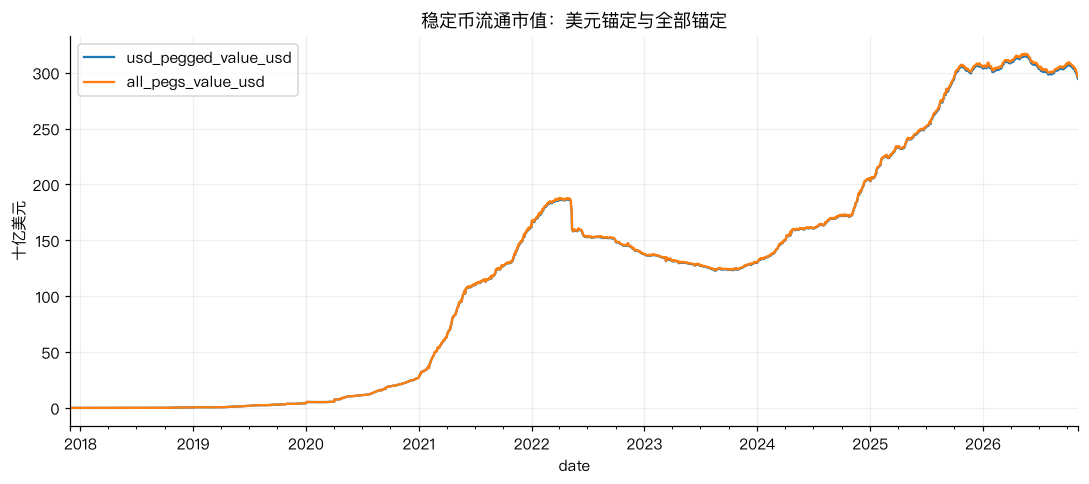

,usd_pegged_value_usd,all_pegs_value_usd
date,,
2026-11-03 00:00:00+00:00,2.960108e+11,2.977989e+11
2026-11-04 00:00:00+00:00,2.951279e+11,2.969220e+11
2026-11-05 00:00:00+00:00,2.945481e+11,2.963459e+11


In [2]:
stable=load_frame("stablecoins").set_index("date").sort_index()
(stable/1e9).plot(title="稳定币流通市值：美元锚定与全部锚定")
plt.ylabel("十亿美元"); plt.tight_layout(); plt.show()
display(stable.tail(3))

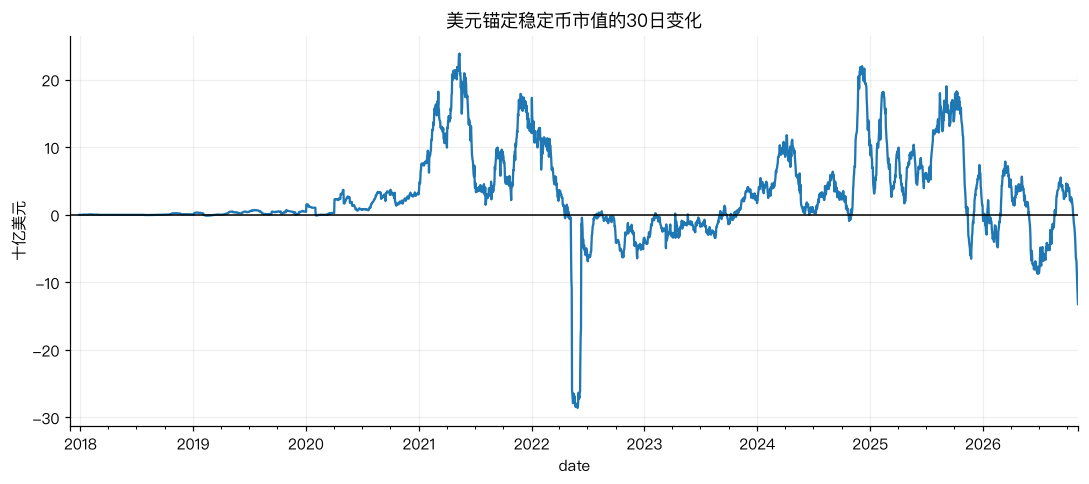

日网格缺值： 0


In [3]:
daily=stable.asfreq("D")
change=daily.usd_pegged_value_usd.diff(30)/1e9
change.plot(title="美元锚定稳定币市值的30日变化")
plt.axhline(0,color="black",linewidth=1); plt.ylabel("十亿美元"); plt.tight_layout(); plt.show()
print("日网格缺值：",int(daily.usd_pegged_value_usd.isna().sum()))

**读图：** 下降提示该覆盖范围内的市值收缩，原因仍可能包括赎回、脱锚、统计口径或覆盖变化。相邻 30 日变化共享 29 天，不能把每个点当成独立实验。

## 2. 再看链上使用，但不混合链的记账方式

`AdrActCnt` 为活跃地址计数；`TxCnt` 为链上交易计数；`FeeTotNtv` 是原生币费用。BTC 的 UTXO 与 ETH 的账户模型不同，不能拿计数高低直接评判商业价值。ETH 主链指标也不覆盖全部 L2 活动。

,首日,末日,价格有效日,地址有效日
asset,,,,
BTC,2015-01-01 00:00:00+00:00,2026-05-24 00:00:00+00:00,4161,4161
ETH,2015-07-30 00:00:00+00:00,2026-05-24 00:00:00+00:00,3942,3951


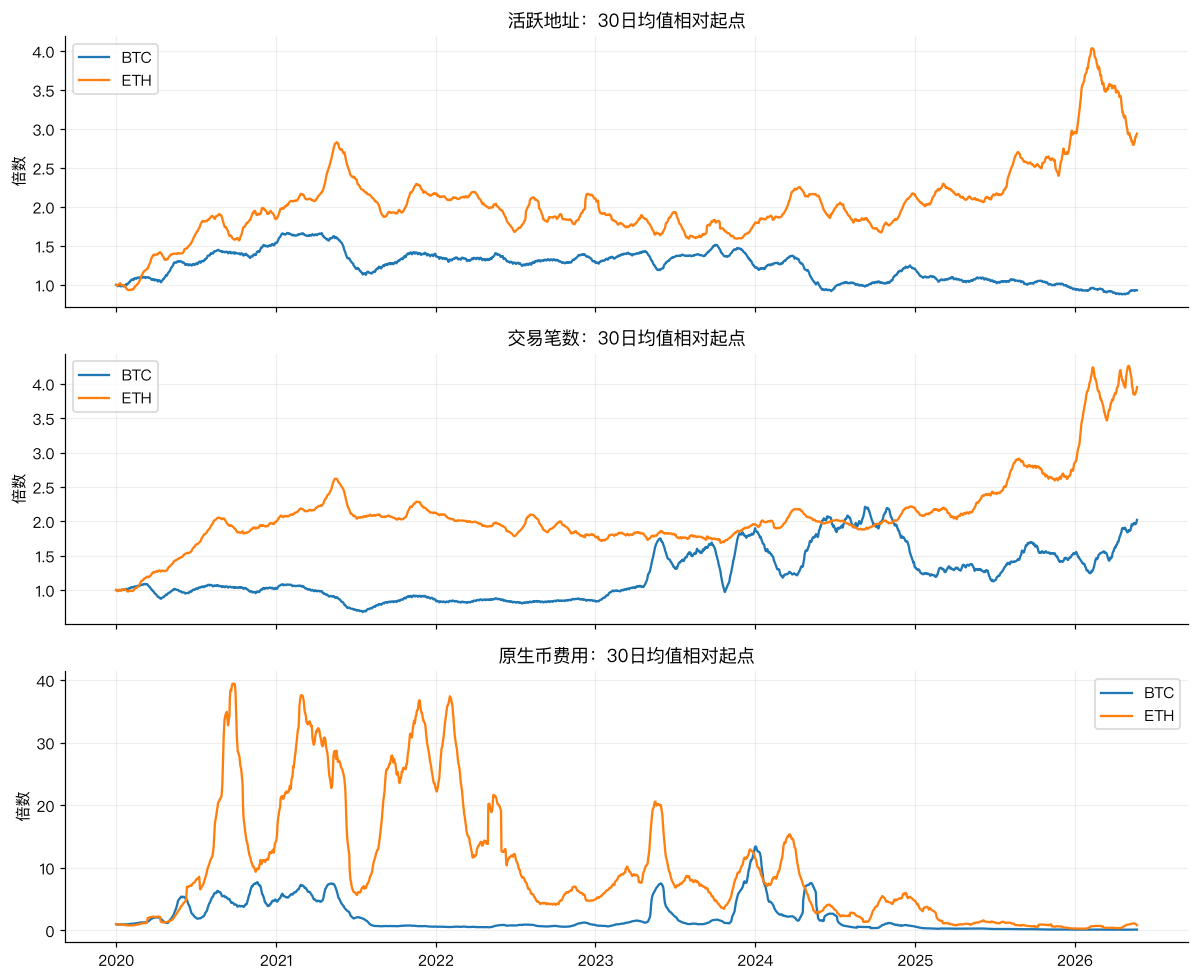

In [4]:
chain=load_frame("onchain")
display(chain.groupby("asset").agg(首日=("date","min"),末日=("date","max"),价格有效日=("PriceUSD","count"),地址有效日=("AdrActCnt","count")))
fig,axs=plt.subplots(3,1,figsize=(11,9),sharex=True)
for asset,g in chain.groupby("asset"):
    g=g.set_index("date").asfreq("D")
    for ax,col in zip(axs,["AdrActCnt","TxCnt","FeeTotNtv"]):
        s=g[col].rolling(30,min_periods=30).mean()
        # 用各链2020年首个有效30日均值归一；这里只比较各自变化，不比较绝对规模。
        s=s.loc["2020-01-01":]; valid=s.dropna()
        ax.plot(s.index,s/valid.iloc[0],label=asset)
for ax,title in zip(axs,["活跃地址：30日均值相对起点","交易笔数：30日均值相对起点","原生币费用：30日均值相对起点"]):
    ax.set_title(title); ax.set_ylabel("倍数"); ax.legend()
plt.tight_layout(); plt.show()

**读图：** 三个图都归一到各自起点，所以只能说明变化倍数。费用增加可能反映拥堵、币价或规则变化，不能自动称为更健康的增长。原件末尾有空值时，滚动窗口不会自动填平。

## 3. 让数据新鲜度成为结果的一部分

网页说“每日更新”不等于这次取得的文件真的更新到今天。必须同时显示最后一条记录日期和最后一个有效指标日期。下面按每个指标单独核对，避免尾部空记录造成虚假的最新日期。

In [5]:
fresh=[]
for asset,g in chain.groupby("asset"):
    for col in ["AdrActCnt","TxCnt","FeeTotNtv","PriceUSD"]:
        dates=g.loc[g[col].notna(),"date"]
        fresh.append({"asset":asset,"metric":col,"last_valid":dates.max(),"nulls":int(g[col].isna().sum())})
display(pd.DataFrame(fresh))

,asset,metric,last_valid,nulls
0,BTC,AdrActCnt,2026-05-23 00:00:00+00:00,1
1,BTC,TxCnt,2026-05-23 00:00:00+00:00,1
2,BTC,FeeTotNtv,2026-05-23 00:00:00+00:00,1
3,BTC,PriceUSD,2026-05-23 00:00:00+00:00,1
4,ETH,AdrActCnt,2026-05-23 00:00:00+00:00,1
5,ETH,TxCnt,2026-05-23 00:00:00+00:00,1
6,ETH,FeeTotNtv,2026-05-23 00:00:00+00:00,1
7,ETH,PriceUSD,2026-05-23 00:00:00+00:00,10


## 4. 能继续研究什么

当前可以做存量变化、链内活动趋势和价格相关性探索。若要研究稳定币支付，需要去除交易所内部转账、机器人、桥接重复和铸币销毁；若研究协议收入，需要明确费用分配给验证者、协议还是代币持有者。这些数据没有在本小包中伪造。

来源：[DefiLlama](https://defillama.com/stablecoins)、[Coin Metrics 社区档案](https://github.com/coinmetrics/data)、[活跃地址定义](https://docs.coinmetrics.io/network-data/network-data-overview/addresses/active-addresses)。Coin Metrics 数据为 CC BY-NC 4.0，本包按个人非商业研究使用。